In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train_df = pd.read_csv("../data/processed/train_data.csv")
test_df = pd.read_csv("../data/processed/test_data.csv")

train_df["date"] = pd.to_datetime(train_df["date"])
test_df["date"] = pd.to_datetime(test_df["date"])

print("Training data:", train_df.shape)
print("Testing data:", test_df.shape)

Training data: (1464, 7)
Testing data: (367, 7)


In [4]:

def create_features(history, current_date):

    features = {}

    # Previous consumption values
    for lag in [1, 2, 3, 7, 14, 28]:
        features[f"lag_{lag}"] = history[-lag]

    # Rolling averages
    for window in [7, 14, 28]:
        features[f"rolling_mean_{window}"] = np.mean(
            history[-window:]
        )

    # Calendar features
    features["day_of_week"] = current_date.day_of_week
    features["month"] = current_date.month
    features["day_of_year"] = current_date.day_of_year
    features["is_weekend"] = int(
        current_date.day_of_week >= 5
    )

    return features

print("Feature function updated!")


Feature function updated!


In [5]:

history = train_df["daily_consumption"].tolist()

X_train = []
y_train = []

for i in range(28, len(history)):

    current_date = train_df.iloc[i]["date"]

    features = create_features(
        history[:i],
        current_date
    )

    X_train.append(features)
    y_train.append(history[i])

X_train = pd.DataFrame(X_train)
y_train = np.array(y_train)

print("XGBoost training data prepared!")
print("Features shape:", X_train.shape)
print("Target shape:", y_train.shape)

display(X_train.head())


XGBoost training data prepared!
Features shape: (1436, 13)
Target shape: (1436,)


,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_14,rolling_mean_28,day_of_week,month,day_of_year,is_weekend
0,51212,50951,50964,54141,49114,41759,52506.142857,50850.785714,49769.035714,4,1,29,0
1,49162,51212,50951,52022,47656,52185,51794.857143,50854.214286,50033.428571,5,1,30,1
2,48306,49162,51212,51503,46939,49846,51264.000000,50900.642857,49894.892857,6,1,31,1
3,49387,48306,49162,56750,48421,50510,50961.714286,51075.500000,49878.500000,0,2,32,0
4,44554,49387,48306,50964,49771,45595,49219.428571,50799.285714,49665.785714,1,2,33,0


In [6]:

from xgboost import XGBRegressor

# Create XGBoost model
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")


XGBoost model trained successfully!


In [7]:

xgb_predictions = []

# Forecast in consecutive 7-day blocks
for start in range(0, len(test_df), 7):

    end = min(start + 7, len(test_df))

    # Historical data available before this block
    history = (
        train_df["daily_consumption"].tolist()
        + test_df["daily_consumption"].iloc[:start].tolist()
    )

    # Predict each day in the block
    for i in range(start, end):

        current_date = test_df.iloc[i]["date"]

        features = pd.DataFrame([
            create_features(history, current_date)
        ])

        prediction = xgb_model.predict(features)[0]

        xgb_predictions.append(prediction)

        # Use predicted value for the next day
        history.append(prediction)

xgb_predictions = np.array(xgb_predictions)

print("XGBoost forecasting completed!")
print("Total predictions:", len(xgb_predictions))


XGBoost forecasting completed!
Total predictions: 367


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
actual = test_df["daily_consumption"].values

xgb_mae = mean_absolute_error(actual, xgb_predictions)

xgb_rmse = np.sqrt(
    mean_squared_error(actual, xgb_predictions)
)

xgb_mape = np.mean(
    np.abs((actual - xgb_predictions) / actual)
) * 100

print("XGBoost Model Performance")
print("-------------------------")
print("MAE:", xgb_mae)
print("RMSE:", xgb_rmse)
print("MAPE:", xgb_mape, "%")

XGBoost Model Performance
-------------------------
MAE: 5355.8505859375
RMSE: 8213.501080538068
MAPE: 7.986466412609758 %


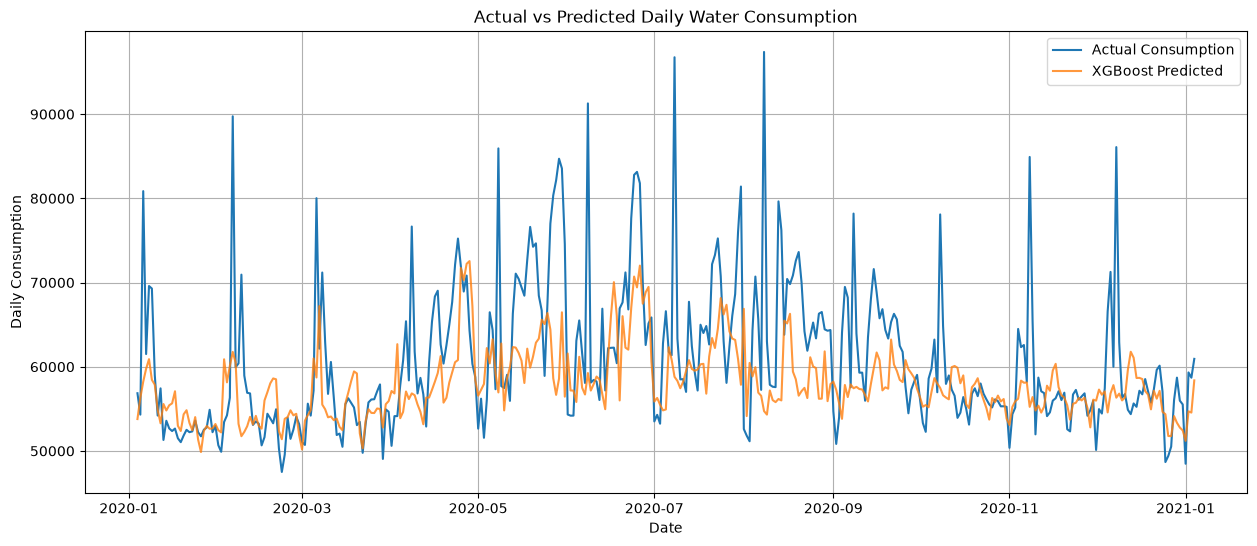

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    test_df["date"],
    actual,
    label="Actual Consumption"
)

plt.plot(
    test_df["date"],
    xgb_predictions,
    label="XGBoost Predicted",
    alpha=0.8
)

plt.title("Actual vs Predicted Daily Water Consumption")
plt.xlabel("Date")
plt.ylabel("Daily Consumption")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import os
import joblib
import pandas as pd

# Create folders if they don't exist
os.makedirs("../results/forecasts", exist_ok=True)
os.makedirs("../results/metrics", exist_ok=True)
os.makedirs("../ml/saved_models", exist_ok=True)

# 1. Save predictions
xgb_results = pd.DataFrame({
    "date": test_df["date"],
    "actual": actual,
    "xgboost_predicted": xgb_predictions
})

xgb_results.to_csv(
    "../results/forecasts/xgboost_predictions.csv",
    index=False
)

# 2. Save evaluation metrics
xgb_metrics = pd.DataFrame({
    "Model": ["XGBoost"],
    "MAE": [xgb_mae],
    "RMSE": [xgb_rmse],
    "MAPE (%)": [xgb_mape]
})

xgb_metrics.to_csv(
    "../results/metrics/xgboost_metrics.csv",
    index=False
)

# 3. Save trained model
joblib.dump(
    xgb_model,
    "../ml/saved_models/xgboost_model.pkl"
)

print("XGBoost results saved successfully!")

XGBoost results saved successfully!


: 